# Holdout embeddings from a bagged recursive partitioner

This notebook trains a `BaggedRecursivePartitionClassifier` on one stratified half of a standard image dataset. It transforms the held-out half into projected partition features, then optionally concatenates those features with the original standardized image features before fitting IMSTE. The projection width matches the original input width, so the combined representation is at most twice the original feature count.

The classifier never sees held-out labels during fitting. IMSTE is transductive, so it embeds the held-out representation; labels are used only for coloring and the optional classifier score. Set up the sister `RecursiveParitionClassifier` checkout next to this repository and install its demo dependencies before running the notebook. Bagging and base-model settings are configurable in the classifier cell.


In [17]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

repo_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'imste' / '__init__.py').is_file()),
    None,
)
if repo_root is None:
    raise RuntimeError('Open this notebook from the IteratedMinimumSpanningTree checkout.')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

rpc_root = repo_root.parent / 'RecursiveParitionClassifier'
if not (rpc_root / 'recursive_partition' / '__init__.py').is_file():
    raise RuntimeError(
        'Expected the sibling RecursiveParitionClassifier checkout at '
        f'{rpc_root}.'
    )
if str(rpc_root) not in sys.path:
    sys.path.insert(0, str(rpc_root))
rpc_notebooks = rpc_root / 'notebooks'
if str(rpc_notebooks) not in sys.path:
    sys.path.insert(0, str(rpc_notebooks))

from recursive_partition import BaggedRecursivePartitionClassifier
from bagged_partition_imste_embeddings import describe_base_models, make_base_models
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.visualization import (
    interactive_force,
    plot_ellipses,
    plot_embedding,
    plot_knn_union,
)
from notebooks.high_dim_mst_gallery import _load_kmnist, _load_openml, _stratified_sample

plt.rcParams['figure.dpi'] = 110


## Select and split the dataset

Select MNIST, Fashion-MNIST, or Kuzushiji-MNIST. `N_SAMPLES` controls the total stratified subset before the 50/50 split. Features are standardized using the training half only, then the same scaler is applied to the held-out half.


In [18]:
DATASET = 'fashion_mnist'  # 'mnist', 'fashion_mnist', or 'kmnist'
N_SAMPLES = 16_000
RANDOM_STATE = 42

DATASET_LOADERS = {
    'mnist': lambda: _load_openml('mnist_784'),
    'fashion_mnist': lambda: _load_openml('Fashion-MNIST'),
    'kmnist': _load_kmnist,
}
DATASET_NAMES = {
    'mnist': 'MNIST',
    'fashion_mnist': 'Fashion-MNIST',
    'kmnist': 'Kuzushiji-MNIST',
}
if DATASET not in DATASET_LOADERS:
    raise ValueError(f'DATASET must be one of {tuple(DATASET_LOADERS)}.')

X_all, y_all = DATASET_LOADERS[DATASET]()
X_all, y_all = _stratified_sample(
    X_all,
    y_all,
    max_samples=N_SAMPLES,
    random_state=RANDOM_STATE,
)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.5,
    stratify=y_all,
    random_state=RANDOM_STATE,
)
input_scaler = StandardScaler()
X_train = input_scaler.fit_transform(X_train_raw.astype(np.float32))
X_test = input_scaler.transform(X_test_raw.astype(np.float32))
obs_test = pd.DataFrame({'class': np.asarray(y_test).astype(str)})

print(
    f'{DATASET_NAMES[DATASET]} · {len(X_train):,} classifier-training rows + '
    f'{len(X_test):,} held-out rows · {X_train.shape[1]:,} input features'
)


Fashion-MNIST · 8,000 classifier-training rows + 8,000 held-out rows · 784 input features


## Configure and fit the bagged recursive partition classifier

Choose a named base model and adjust bagging settings below. `BASE_MODELS` includes the same Linear/Quadratic/RBF SVM, QDA, MLP, and Gaussian-process options as the sister notebook. The selected classifier is fit on the training half only. The ensemble's `n_components` projects its partition paths down to the original input width. We fit a scaler on the training projection and apply it to the held-out projection before optional concatenation.


In [19]:
BAGGING_N_ESTIMATORS = 100
MAX_DEPTH = 5

# A wider/deeper MLP can represent more complex class partitions.
MLP_HIDDEN_LAYER_SIZES = (64, 64, 32)
BASE_MODELS = make_base_models(
    max_depth=MAX_DEPTH,
    mlp_hidden_layer_sizes=MLP_HIDDEN_LAYER_SIZES,
)
describe_base_models(BASE_MODELS)

# Choose exactly one model for this notebook run.
MODELS_TO_RUN = ['Linear SVM']
if len(MODELS_TO_RUN) != 1:
    raise ValueError('Choose exactly one base model in MODELS_TO_RUN.')
MODEL_NAME = MODELS_TO_RUN[0]
if MODEL_NAME not in BASE_MODELS:
    raise ValueError(f'Unknown model {MODEL_NAME!r}; choose from {tuple(BASE_MODELS)}.')

# Match the projected partition feature count to the original image width.
N_PARTITION_COMPONENTS = X_train.shape[1]
INCLUDE_ORIGINAL_FEATURES = True

# Full BaggedRecursivePartitionClassifier configuration.
CLASSIFIER_PARAMETERS = {
    'estimator': None,  # Set to the selected BASE_MODELS entry below.
    'n_estimators': BAGGING_N_ESTIMATORS,
    'max_samples': 1.0,
    'bootstrap': True,
    'n_jobs': -1,
    'random_state': RANDOM_STATE,
    'aggregation': 'mean_proba',
    'oob_score': False,
    'verbose': 0,
    'max_depth': MAX_DEPTH,
    'n_components': N_PARTITION_COMPONENTS,
}
classifier_parameters = dict(CLASSIFIER_PARAMETERS)
classifier_parameters['estimator'] = BASE_MODELS[MODEL_NAME]

classifier = BaggedRecursivePartitionClassifier(**classifier_parameters)
classifier.fit(X_train, y_train)
partition_train = classifier.transform(X_train)
partition_test = classifier.transform(X_test)

partition_scaler = StandardScaler()
partition_scaler.fit(partition_train)
partition_test_scaled = partition_scaler.transform(partition_test)
if partition_test_scaled.shape[1] != X_test.shape[1]:
    raise ValueError('Projected partition width must match the original feature width.')
if INCLUDE_ORIGINAL_FEATURES:
    imste_features = np.hstack((X_test, partition_test_scaled))
else:
    imste_features = partition_test_scaled

print(f'Model: {MODEL_NAME}')
print(f'Bagged classifiers: {len(classifier.estimators_)}')
print(f'Projected train features: {partition_train.shape}')
print(f'Projected held-out features: {partition_test_scaled.shape}')
print(f'Original held-out features: {X_test.shape}')
print(f'IMSTE input features: {imste_features.shape}')
print(f'Held-out classifier accuracy: {classifier.score(X_test, y_test):.3f}')


Available recursive partition models
Linear SVM
  partition depth: 5
  split estimator: SVC(kernel='linear', C=10.0, class_weight='balanced')
Quadratic SVM
  partition depth: 5
  split estimator: SVC(kernel='poly', degree=2, coef0=1.0, gamma='scale', C=1.0, class_weight='balanced')
RBF SVM
  partition depth: 5
  split estimator: SVC(kernel='rbf', gamma='scale', C=1.0, class_weight='balanced')
QDA
  partition depth: 5
  split estimator: EqualPriorQDA(reg_param=0.05)
MLP
  partition depth: 5
  split estimator: MLPClassifierAdapter(hidden_layer_sizes=(64, 64, 32), solver='adam', max_iter=1000, tol=0.01, class_weight='balanced', random_state=42)
Gaussian process
  partition depth: 5
  split estimator: GaussianProcessClassifierAdapter(optimizer=None, max_iter_predict=50, class_weight='balanced', random_state=42)
Model: Linear SVM
Bagged classifiers: 100
Projected train features: (8000, 784)
Projected held-out features: (8000, 784)
Original held-out features: (8000, 784)
IMSTE input features

## Fit IMSTE to the held-out representation

By default, IMSTE receives the held-out original image features concatenated with the equally wide projected partition features. Set `INCLUDE_ORIGINAL_FEATURES = False` to embed only the projected partition features. The class labels are not passed to IMSTE.


In [20]:
IMSTE_PARAMETERS = {
    'n_msts': 40,
    'n_epochs': 2000,
    'mst_method': 'famst',
    'mst_neighbors': 256,
    'negative_ratio': 30,
    'device': 'mps',
    'random_state': RANDOM_STATE,
}

mapper = IteratedMinimumSpanningTreeEmbedder(**IMSTE_PARAMETERS)
embedding = mapper.fit_transform(imste_features)
print(f'Embedding shape: {embedding.shape}')
print(f'Graph build: {mapper.graph_construction_time_:.2f}s · fit: {mapper.fit_time_:.2f}s')


Embedding shape: (8000, 2)
Graph build: 5.97s · fit: 43.50s


## 1. Colored held-out embedding


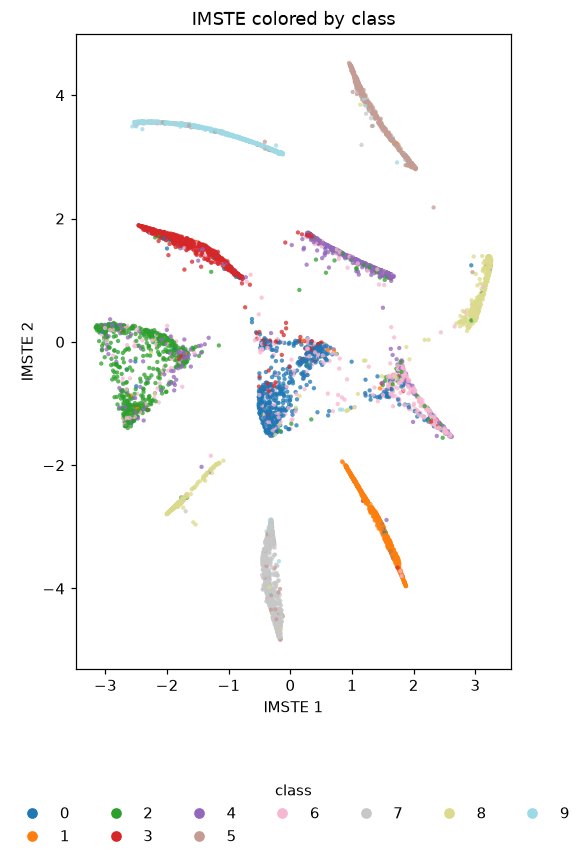

In [21]:
fig, ax = plot_embedding(
    mapper,
    obs_test,
    color_keys=('class',),
    point_size=8,
    point_alpha=0.75,
    legend_position='bottom',
)
plt.show()


## 2. kNN neighborhood union


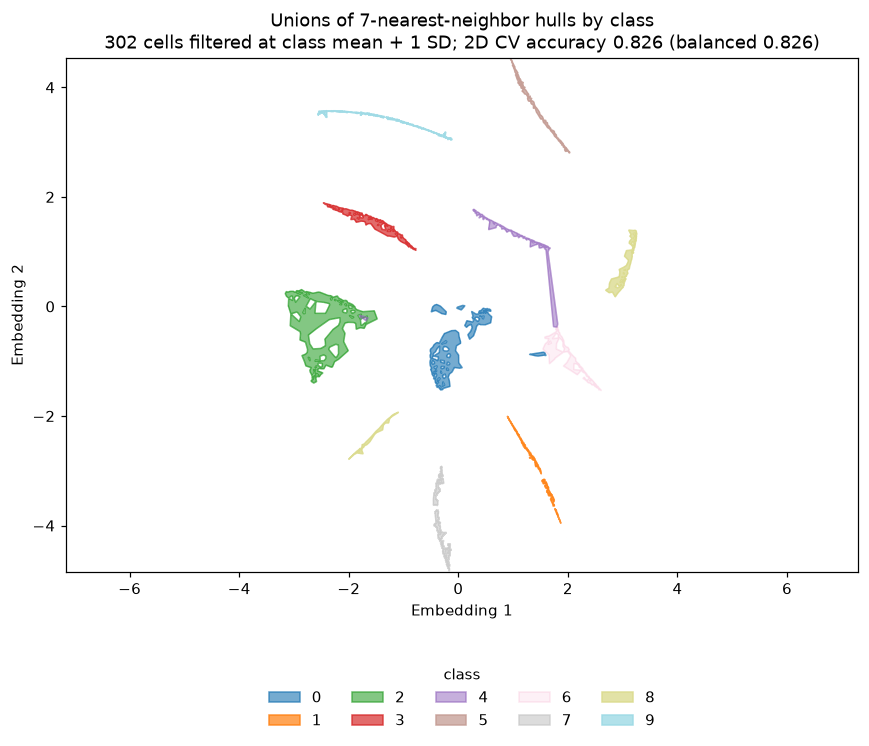

In [22]:
KNN_VIEW = {
    'k': 7,
    'cv_neighbors': 5,
    'cv_splits': 5,
    'random_state': RANDOM_STATE,
    'distance_std_threshold': 1.0,
    'alpha_range': (0.2, 0.8),
    'legend_position': 'bottom',
}
fig, ax = plot_knn_union(mapper, obs_test, label_key='class', **KNN_VIEW)
plt.show()


## 3. Fitted ellipses


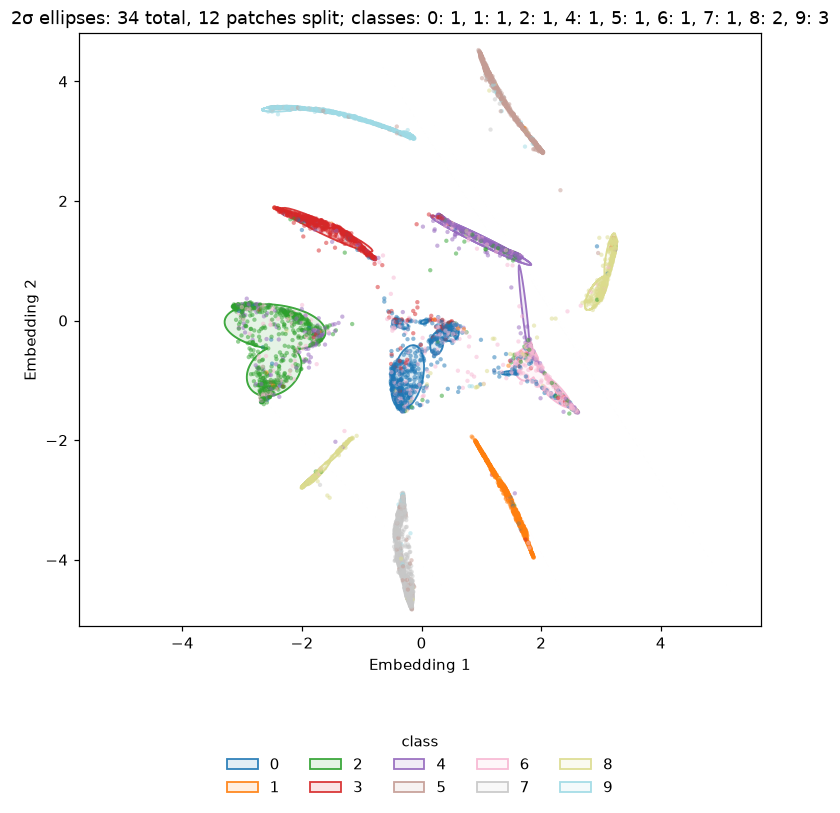

In [23]:
ELLIPSE_VIEW = {
    'k': KNN_VIEW['k'],
    'cv_neighbors': KNN_VIEW['cv_neighbors'],
    'cv_splits': KNN_VIEW['cv_splits'],
    'random_state': RANDOM_STATE,
    'distance_std_threshold': KNN_VIEW['distance_std_threshold'],
    'n_std': 2.0,
    'max_ellipses_per_region': 2,
    'min_precision': 0.7,
    'min_recall': 0.7,
    'point_size': 8,
    'point_alpha': 0.5,
    'legend_position': 'bottom',
}
fig, ax = plot_ellipses(mapper, obs_test, label_key='class', **ELLIPSE_VIEW)
plt.show()


## 4. Interactive force view


In [24]:
force_view = interactive_force(
    mapper,
    obs_test,
    label_key='class',
    initial_k=8,
    initial_iterations=20,
    initial_distance_fraction=0.3,
    max_k=30,
    max_iterations=150,
    point_size=8,
)
display(force_view)
